# Web Technologies

**Seong Cho** · ACME Data Science Essentials, Lab 4

**Lab objective:** serialize data with JSON, and use sockets to build a simple server and client that communicate over the network; then pull data from a web API.

<sub>Lab specification from the *Data Science Essentials* lab manual of [Foundations of Applied Mathematics](https://foundations-of-applied-mathematics.github.io/) (BYU ACME), © Dr. J. Humpherys, used under [CC BY 3.0 US](http://creativecommons.org/licenses/by/3.0/us/). Problem statements are quoted from my lab template and the spec; the notes are condensed from the spec. Solutions are my own.</sub>

In [1]:
# solutions.py
# """Volume 3: Web Technologies. Solutions File."""
import json
import socket
import matplotlib.pyplot as plt
import numpy as np
import re
import time

## Data serialization with JSON

**Serialization** packages data so it is easy to transmit and rebuild on another computer or in another language; **deserialization** rebuilds the object. The dominant format on the web is **JSON** (JavaScript Object Notation, though language-independent), built from two structures: key/value collections and ordered lists, like Python's `dict` and `list`. A string in JSON format representing one piece of data is a **JSON message**.

| Function | Does |
|---|---|
| `json.dumps(obj)` / `json.dump(obj, file)` | object → JSON message (string / written to an open file) |
| `json.loads(s)` / `json.load(file)` | JSON message → object |

> **Note.** A Jupyter Notebook (`.ipynb`) file is itself JSON: open one in a text editor to see the cells with their `"cell_type"` and `"source"` keys.

In [2]:
my_car = {"car": {"make": "Ford", "color": [255, 30, 30]}, "owner": "me"}
car_str = json.dumps(my_car)
print(car_str)
print(json.loads(car_str) == my_car)

{"car": {"make": "Ford", "color": [255, 30, 30]}, "owner": "me"}
True


## Problem 1: NYC traffic accidents

> **Problem 1.** Load the data from the specified JSON file. Look at the first few entries of the dataset and decide how to gather information about the cause(s) of each accident. Make a readable, sorted bar chart showing the total number of times that each of the 7 most common reasons for accidents are listed in the data set.

The spec's check: the 6th most common reason is "Backing Unsafely," listed 59 times.

In [3]:
# Problem 1
def prob1(filename="nyc_traffic.json"):
    """Load the data from the specified JSON file. Look at the first few
    entries of the dataset and decide how to gather information about the
    cause(s) of each accident. Make a readable, sorted bar chart showing the
    total number of times that each of the 7 most common reasons for accidents
    are listed in the data set.
    """
    # Open the file and load the data
    with open(filename, 'r') as infile:
        nyc_traffic = json.load(infile)

    # Make an empty dictionary
    cause_dict = dict()
    # Enumerate through the data and store each of the cause of accidents as
    # keys of the dictionary. Then, count up how many occurrances there are and
    # store it as a corresponding value of the dictionary.
    for i, n in enumerate(nyc_traffic):
        try:
            key1 = n['contributing_factor_vehicle_1']
            if key1 in cause_dict:
                cause_dict[key1] += 1
            else:
                cause_dict[key1] = 1
        except KeyError:
            continue

        try:
            key2 = n['contributing_factor_vehicle_2']
            if key2 in cause_dict:
                cause_dict[key2] += 1
            else:
                cause_dict[key2] = 1
        except KeyError:
            continue

    # Convert to tuple and sort
    cause_tup = [(k,v) for k,v in cause_dict.items()]
    cause_tup.sort(reverse=True, key=lambda x: x[1])
    # Store the causes and counts in separate arrays
    cause_reason = [k for k,v in cause_tup[:7]]
    cause_count = [v for k,v in cause_tup[:7]]
    print(cause_count)

    # Graph with a barh plot
    fig, ax = plt.subplots()
    index = np.arange(7)
    bars = ax.barh(index, cause_count)
    
    ax.set_xlabel('number of occurrences')
    ax.set_ylabel('cause')
    ax.set_yticks(index)
    ax.set_yticklabels(cause_reason)
    ax.set_title('Top 7 causes of accidents in NYC')
    fig.tight_layout()
    plt.show()

[946, 291, 108, 75, 61, 59, 46]


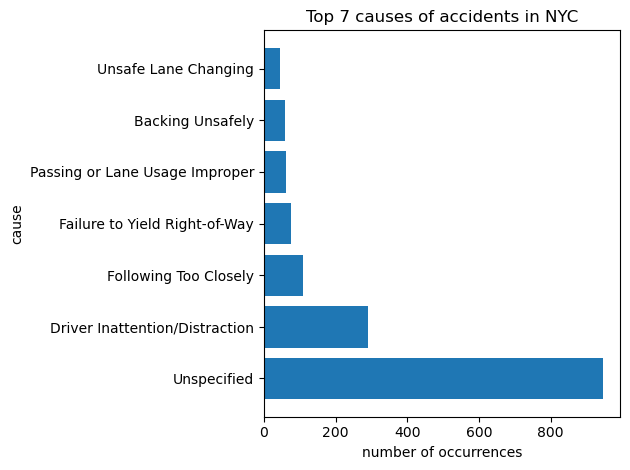

In [4]:
prob1()

## Custom encoders and decoders

The default encoder can't serialize everything (a `set`, for instance). Subclass `json.JSONEncoder` and override `default()` to turn the object into nested lists and dicts, typically `{"dtype": <type name>, "data": <contents>}`; the matching decoder is passed as `object_hook` to `json.loads()` and rebuilds the object from that layout. Both should raise an error when handed something they weren't written for.

> **Note.** `pickle` serializes with almost the same interface (`pickle.dumps`, `pickle.loads`) and is a good choice when the data will only be unpacked in Python. YAML and XML are other formats, but JSON dominates on the web.

## Problem 2: Tic-tac-toe encoder and decoder

> **Problem 2.** The following class facilitates a regular $3 \times 3$ game of tic-tac-toe, where the boxes in the board have the following coordinates.
>
> | | | |
> |---|---|---|
> | (0, 0) | (0, 1) | (0, 2) |
> | (1, 0) | (1, 1) | (1, 2) |
> | (2, 0) | (2, 1) | (2, 2) |
>
> Write a custom encoder and decoder for the `TicTacToe` class. If the custom encoder receives anything other than a `TicTacToe` object, raise a `TypeError`.

In [5]:
# Given in the lab.
class TicTacToe:
    def __init__(self):
        """Initialize an empty board. The O's go first."""
        self.board = [[' ']*3 for _ in range(3)]
        self.turn, self.winner = "O", None

    def move(self, i, j):
        """Mark an O or X in the (i,j)th box and check for a winner."""
        if self.winner is not None:
            raise ValueError("the game is over!")
        elif self.board[i][j] != ' ':
            raise ValueError("space ({},{}) already taken".format(i,j))
        self.board[i][j] = self.turn

        # Determine if the game is over.
        b = self.board
        if any(sum(s == self.turn for s in r)==3 for r in b):
            self.winner = self.turn     # 3 in a row.
        elif any(sum(r[i] == self.turn for r in b)==3 for i in range(3)):
            self.winner = self.turn     # 3 in a column.
        elif b[0][0] == b[1][1] == b[2][2] == self.turn:
            self.winner = self.turn     # 3 in a diagonal.
        elif b[0][2] == b[1][1] == b[2][0] == self.turn:
            self.winner = self.turn     # 3 in a diagonal.
        else:
            self.turn = "O" if self.turn == "X" else "X"

    def empty_spaces(self):
        """Return the list of coordinates for the empty boxes."""
        return [(i,j) for i in range(3) for j in range(3)
                                        if self.board[i][j] == ' ' ]
    def __str__(self):
        return "\n---------\n".join(" | ".join(r) for r in self.board)

In [6]:
# Problem 2
class TicTacToeEncoder(json.JSONEncoder):
    """A custom JSON Encoder for TicTacToe objects."""
    def default(self, obj):
        if not isinstance(obj, TicTacToe):
            raise TypeError("expected a TicTacToe object for encoding")
        return {"dtype": "TicTacToe", "data": [obj.board, obj.turn, obj.winner]}


# Problem 2
def tic_tac_toe_decoder(obj):
    """A custom JSON decoder for TicTacToe objects."""
    if "dtype" in obj:
        if obj["dtype"] != "TicTacToe" or "data" not in obj:
            raise ValueError("expected a JSON message from TicTacToeEncoder")
        ttt = TicTacToe()
        # Define the parameters based on the object
        ttt.board = obj["data"][0]
        ttt.turn = obj["data"][1]
        ttt.winner = obj["data"][2]
        return ttt
    raise ValueError("expected a JSON message from TicTacToeEncoder")

In [7]:
# Problem 2
T = TicTacToe()
T.move(1,1)
ttt_message = json.dumps(T, cls=TicTacToeEncoder)
print(ttt_message)
T2 = json.loads(ttt_message, object_hook=tic_tac_toe_decoder)
print(T2)
print(T2.turn, T2.winner)

{"dtype": "TicTacToe", "data": [[[" ", " ", " "], [" ", "O", " "], [" ", " ", " "]], "X", null]}
  |   |  
---------
  | O |  
---------
  |   |  
X None


## Servers and clients

Most network communication uses the protocols of the Internet Protocol Suite. **TCP** opens a connection between two computers, exchanges *packets*, and closes the connection; it does so through **sockets**, addresses within a computer where a program sends or receives data (like a P.O. box in a post office).

A **server** provides functionality to **client** programs. With Python's `socket` module, a server creates a socket (`socket.AF_INET, socket.SOCK_STREAM`), `bind()`s it to an address `(host, port)`, and `listen()`s; `accept()` then blocks until a client connects and returns a new connection socket. Data travels as bytes: `recv(n)` + `decode()` to read, `encode()` + `sendall()` to write. A client makes the same kind of socket and calls `connect(server_address)`, then sends and receives on that socket itself. The host `"0.0.0.0"` (or `"localhost"`) means the local machine.

> **Achtung!** Only use port numbers greater than 1023 to avoid interrupting standard system services. It can take a while for a port to reopen after a server closes, so wait a few seconds between tests or use different ports.

The lab's example: a server that echoes strings back reversed, and its client.

In [8]:
def mirror_server(server_address=("0.0.0.0", 33333)):
    """A server for reflecting strings back to clients in reverse order."""
    print("Starting mirror server on {}".format(server_address))

    # Specify the socket type, which determines how clients will connect.
    server_sock = socket.socket(socket.AF_INET, socket.SOCK_STREAM)
    server_sock.bind(server_address)    # Assign this socket to an address.
    server_sock.listen(1)               # Start listening for clients.

    while True:
        # Wait for a client to connect to the server.
        print("\nWaiting for a connection...")
        connection, client_address = server_sock.accept()

        try:
            # Receive data from the client.
            print("Connection accepted from {}.".format(client_address))
            in_data = connection.recv(1024).decode()    # Receive data.
            print("Received '{}' from client".format(in_data))

            # Process the received data and send something back to the client.
            out_data = in_data[::-1]
            print("Sending '{}' back to the client".format(out_data))
            connection.sendall(out_data.encode())       # Send data.

        # Make sure the connection is closed securely.
        finally:
            connection.close()
            print("Closing connection from {}".format(client_address))

def mirror_client(server_address=("0.0.0.0", 33333)):
    """A client program for mirror_server()."""
    print("Attempting to connect to server at {}...".format(server_address))

    # Set up the socket to be the same type as the server.
    client_sock = socket.socket(socket.AF_INET, socket.SOCK_STREAM)
    client_sock.connect(server_address)    # Attempt to connect to the server.
    print("Connected!")

    # Send some data from the client user to the server.
    out_data = input("Type a message to send: ")
    client_sock.sendall(out_data.encode())              # Send data.

    # Wait to receive a response back from the server.
    in_data = client_sock.recv(1024).decode()           # Receive data.
    print("Received '{}' from the server".format(in_data))

    # Close the client socket.
    client_sock.close()

## Problem 3: Tic-tac-toe server

> **Problem 3.** Write a function that accepts a `(host, port)` tuple and starts up a tic-tac-toe server at the specified location. Wait to accept a connection, then while the connection is open, repeat the following operations.
> 1. Receive a JSON serialized `TicTacToe` object (serialized with your custom encoder from Problem 2) from the client.
> 2. Deserialize the `TicTacToe` object using your custom decoder from Problem 2.
> 3. If the client has just won the game, send `"WIN"` back to the client and close the connection.
> 4. If there is no winner but board is full, send `"DRAW"` to the client and close the connection.
> 5. If the game still isn't over, make a random move on the tic-tac-toe board and serialize the updated `TicTacToe` object. If this move wins the game, send `"LOSE"` to the client, then send the serialized object separately (as proof), and close the connection. Otherwise, send only the updated `TicTacToe` object back to the client but keep the connection open.
>
> (Hint: print information at each step so you can see what the server is doing.)
>
> Ensure that the connection closes securely even if an exception is raised. Note that you will not be able to fully test your server until you have written a client (see Problem 4).

In [9]:
# Problem 3
def tic_tac_toe_server(server_address=("0.0.0.0", 60000)):
    """A server for playing tic-tac-toe with random moves."""
    print("Starting mirror server on {}".format(server_address))

    # Specify the socket type, which determines how clients will connect.
    server_sock = socket.socket(socket.AF_INET, socket.SOCK_STREAM)
    server_sock.bind(server_address)    # Assign this socket to an address.
    server_sock.listen(1)               # Start listening for clients.

    while True:
        # Wait for a client to connect to the server.
        print("\nWaiting for a connection...")
        connection, client_address = server_sock.accept()
        # Receive data from the client.
        print("Connection accepted from {}.".format(client_address))

        while True:
            in_data = connection.recv(1024).decode()    # Receive data.
            print("Received '{}' from client".format(in_data))
            T = json.loads(in_data, object_hook=tic_tac_toe_decoder)
            # If the player won, send WIN
            if T.winner == 'O':
                out_data = "WIN"
                print("Sending '{}' back to the client".format(out_data))
                connection.sendall(out_data.encode())
                break
            # If the board is filled with no winner, send DRAW
            elif T.winner == None and len(T.empty_spaces()) == 0:
                out_data = "DRAW"
                print("Sending '{}' back to the client".format(out_data))
                connection.sendall(out_data.encode())
                break
            # Make a random move
            i = np.random.randint(len(T.empty_spaces()))
            T.move(T.empty_spaces()[i][0], T.empty_spaces()[i][1])
            # If the computer wins, then send LOSE along with the final board
            if T.winner == 'X':
                out_data = "LOSE"
                print("Sending '{}' back to the client".format(out_data))
                connection.sendall(out_data.encode())
                # Sleep for a tiny bit so that the two out_data doesn't get sent as one
                time.sleep(0.1)
                out_data2 = json.dumps(T, cls=TicTacToeEncoder)
                print("Sending '{}' back to the client".format(out_data2))
                connection.sendall(out_data2.encode())
                break
            # If none of the above occurs, send the updated configuration of the board
            out_data = json.dumps(T, cls=TicTacToeEncoder)
            print("Sending '{}' back to the client".format(out_data))
            connection.sendall(out_data.encode())       # Send data.
        # Make sure the connection is closed securely.
        connection.close()
        print("Closing connection from {}".format(client_address))

## Problem 4: Tic-tac-toe client

> **Problem 4.** Write a function that accepts a `(host, port)` tuple and connects to the tic-tac-toe server at the specified location. Start by initializing a new `TicTacToe` object, then repeat the following steps until the game is over.
> 1. Print the board and prompt the player for a move. Continue prompting the player until they provide valid input.
> 2. Update the board with the player's move, then serialize it using your custom encoder from Problem 2, and send the serialized version to the server.
> 3. Receive a response from the server. If the game is over, congratulate or mock the player appropriately. If the player lost, receive a second response from the server (the final game board), deserialize it, and print it out.
>
> Close the connection once the game ends.

In [10]:
# Problem 4
def tic_tac_toe_client(server_address=("0.0.0.0", 60000)):
    """A client program for tic_tac_toe_server()."""
    print("Attempting to connect to server at {}...".format(server_address))

    # Set up the socket to be the same type as the server.
    client_sock = socket.socket(socket.AF_INET, socket.SOCK_STREAM)
    client_sock.connect(server_address)    # Attempt to connect to the server.
    print("Connected!")

    # Send some data from the client user to the server.
    T = TicTacToe()              # Send data.

    while True:
        # print T
        print(T)
        # prompt in try block so that prompt is repeated if invalid input is given
        try:
            prompt = input("Make your move: ")
            T.move(int(prompt.split(',')[0]), int(prompt.split(',')[1]))
        except:
            # Way to escape the client (cause Ctrl+C won't work with this method)
            if prompt == "exit":
                break
            continue
        # updated T
        print(T)
        # Encode T to send to server
        ttt_message = json.dumps(T, cls=TicTacToeEncoder)
        client_sock.sendall(ttt_message.encode())

        # Wait to receive a response back from the server.
        in_data = client_sock.recv(1024).decode()           # Receive data.
        # Actions to take when the game is over
        if in_data == "WIN" or in_data == "DRAW" or in_data == "LOSE":
            if in_data == "WIN":
                print("Congratulations! You win!")
            if in_data == "DRAW":
                print("DRAW!")
            if in_data == "LOSE":
                print("You lost to the computer thats literally playing randomly.")
                in_data2 = client_sock.recv(1024).decode()
                T = json.loads(in_data2, object_hook=tic_tac_toe_decoder)
                print("Final board\n" + str(T))
            break
        # If the game is ongoing, then decode T and continue the game
        T = json.loads(in_data, object_hook=tic_tac_toe_decoder)
        print("The computer has made his move")

    # Close the client socket.
    client_sock.close()

> **Note.** The next two cells are not run in this notebook: the server blocks forever waiting for connections and the client reads moves from `input()`. Run them in two separate Python sessions, server first.

In [ ]:
# Session 1
np.random.seed(0)
tic_tac_toe_server()

In [ ]:
# Session 2
tic_tac_toe_client()

## APIs

An **API** (Application Program Interface) is a server that listens for requests from authorized users and answers with data at its **endpoints**. Each API documents its own request and authentication syntax. The `requests` module is the standard way to call one: `requests.get(endpoint).json()`.

> **Achtung!** Every website and API has a policy for automated data retrieval and use, usually summarized in its `robots.txt` (e.g. https://www.google.com/robots.txt). Ignoring it can have severe legal consequences.

## Problem 5: Download NYC data

> **Problem 5.** Make requests to download data from the following API endpoints.
>
> Recycling bin locations: https://data.cityofnewyork.us/api/views/sxx4-xhzg/rows.json?accessType=DOWNLOAD
>
> Residential addresses: https://data.cityofnewyork.us/api/views/7823-25a9/rows.json?accessType=DOWNLOAD
>
> Save the recycling bin data as `nyc_recycling.json` and the residential address data as `nyc_addresses.json`.

*Not completed.*

In [11]:
# Problem 5
def download_nyc_data():
    """Make requests to download data from the following API endpoints.

    Recycling bin locations: https://data.cityofnewyork.us/api/views/sxx4-xhzg/rows.json?accessType=DOWNLOAD

    Residential addresses: https://data.cityofnewyork.us/api/views/7823-25a9/rows.json?accessType=DOWNLOAD

    Save the recycling bin data as nyc_recycling.json and the residential
    address data as nyc_addresses.json.
    """
    raise NotImplementedError("Problem 5 Incomplete")

## Problem 6: Distance to the nearest recycling bin

> **Problem 6.** Load the specified data files. Use a k-d tree to determine the distances from each address to the nearest recycling bin, and plot a histogram of the results.
>
> DO NOT call `download_nyc_data()` in this function.

*Not completed.*

In [12]:
# Problem 6
def prob6(recycling="nyc_recycling.json", addresses="nyc_addresses.json"):
    """Load the specifiec data files. Use a k-d tree to determine the distances
    from each address to the nearest recycling bin, and plot a histogram of
    the results.

    DO NOT call download_nyc_data() in this function.
    """
    raise NotImplementedError("Problem 6 Incomplete")